In [ ]:
Live URL: https://mlassignmentheartdisease-ypcmhkkqldabnirnnqjurz.streamlit.app/
Github Link: https://github.com/Hamza1086/MLAssignment_HeartDisease


---
# Heart Disease Prediction System

## Introduction
**Definition:** A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) from four simple patient attributes.

**Application:** Early screening support and learning how medical risk factors relate to heart disease. (Teaching demo only, not a medical device.)

**Dataset:** UCI Heart Disease Dataset (Cleveland database, 303 patients) – https://archive.ics.uci.edu/dataset/45/heart+disease

### Inputs (4 attributes selected from the 13 available)
| Input Attribute | UCI Column | Possible Values |
| --- | --- | --- |
| **ChestPain** | `cp` | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **Gender** | `sex` | Male, Female |
| **ExerciseAngina** | `exang` | Yes, No |
| **MajorVessels** | `ca` | Zero, One, Two, Three (vessels coloured by fluoroscopy) |

### Output
| Output Attribute | Possible Values |
| --- | --- |
| **Disease** | Yes, No |

**Why these 4?** The inputs are all categorical (like Titanic's PClass/Gender/Sibling/Embarked), so the same Label-Encoding pipeline applies unchanged. They are also strong predictors in the data and easy for a user to answer. Several attribute combinations were compared and this one gave about 85% accuracy with a simple SVC.

## Table of Contents
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction (select 4 attributes)
- Step 5: Label Encoding (5.1 train encoders, 5.2 encode output, 5.3 encode input)
- Step 6: Training Phase (split, train SVC, save model)
- Step 7: Testing Phase (load model, predict, accuracy, detailed metrics)
- Step 8: Application Phase (user input → prediction)
- Step 9: Feedback Phase
- Step 10: Deployment

### Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable

### Step 2: Load Sample Data
The raw UCI (Cleveland) data is stored in `heart.csv` (numeric codes, 14 columns).

In [2]:
raw_data = pd.read_csv("heart.csv", encoding="utf-8-sig")
print("Raw data:")
print("=========\n")
print(raw_data.head(10))

Raw data:

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   
5   57    1   0       140   192    0        1      148      0      0.4      1   
6   56    0   1       140   294    0        0      153      0      1.3      1   
7   44    1   1       120   263    0        1      173      0      0.0      2   
8   52    1   2       172   199    1        1      162      0      0.5      2   
9   57    1   2       150   168    0        1      174      0      1.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0    

### Step 3: Understand and Pre-process Sample Data
#### Step 3.1: Understand Sample Data

In [3]:
print("Attributes in raw data:")
print("=======================\n")
print(list(raw_data.columns))
print("\nNumber of instances:", len(raw_data))
print("Missing values:", int(raw_data.isna().sum().sum()))

print("\nValue counts of the 4 attributes we will use:")
for col in ["cp", "sex", "exang", "ca"]:
    print(f"\n{col}:")
    print(raw_data[col].value_counts().sort_index().to_string())

print("\ntarget (as stored in this file):")
print(raw_data["target"].value_counts().sort_index().to_string())

Attributes in raw data:

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Number of instances: 303
Missing values: 0

Value counts of the 4 attributes we will use:

cp:
cp
0    143
1     50
2     87
3     23

sex:
sex
0     96
1    207

exang:
exang
0    204
1     99

ca:
ca
0    175
1     65
2     38
3     20
4      5

target (as stored in this file):
target
0    138
1    165


#### Step 3.2: Pre-process Sample Data
Three cleaning issues were found in the raw file:

1. **Inverted label.** In this copy of the dataset `target = 1` actually means *no disease* (patients with target 1 have higher max heart rate and lower ST depression, which is typical of healthy hearts). The original UCI `num` column uses 0 = no disease. So we flip it: **Disease = Yes when target == 0**.
2. **`ca` = 4 is invalid.** `ca` (major vessels) can only be 0–3; value 4 is an artefact for missing data. These 5 rows are removed.
3. **Numeric codes → readable text.** Codes are replaced with category names so the Label Encoder can be used exactly like in the Titanic system.

In [4]:
# Evidence that target==1 means "healthy" (healthy hearts reach a higher max heart rate)
print(raw_data.groupby("target")[["thalach", "oldpeak"]].mean().round(2))

# 1) remove invalid rows (ca must be 0-3)
data = raw_data[raw_data["ca"] <= 3].copy()
print("\nRows removed (ca = 4):", len(raw_data) - len(data))

# 2) convert numeric codes to readable categories
data["ChestPain"] = data["cp"].map({0: "Asymptomatic", 1: "Atypical Angina",
                                    2: "Non-Anginal Pain", 3: "Typical Angina"})
data["Gender"] = data["sex"].map({1: "Male", 0: "Female"})
data["ExerciseAngina"] = data["exang"].map({1: "Yes", 0: "No"})
data["MajorVessels"] = data["ca"].map({0: "Zero", 1: "One", 2: "Two", 3: "Three"})
data["Disease"] = data["target"].map({0: "Yes", 1: "No"})   # flipped label

# sanity check: asymptomatic chest pain should show the highest disease rate
print("\nDisease rate by chest pain type (sanity check):")
print((data["Disease"].eq("Yes").groupby(data["ChestPain"]).mean() * 100).round(1).astype(str) + " %")

        thalach  oldpeak
target                  
0        139.10     1.59
1        158.47     0.58

Rows removed (ca = 4): 5

Disease rate by chest pain type (sanity check):
ChestPain
Asymptomatic        72.5 %
Atypical Angina     18.4 %
Non-Anginal Pain    21.4 %
Typical Angina      30.4 %
Name: Disease, dtype: object


### Step 4: Feature Extraction
Only **4 input attributes** are selected (assignment constraint), plus the output.

In [5]:
sample_data = data[["ChestPain", "Gender", "ExerciseAngina", "MajorVessels", "Disease"]].reset_index(drop=True)
sample_data.to_csv("sample-data.csv", index=False)
print(sample_data.head(10))
print("\nShape:", sample_data.shape)
print("\nClass balance:")
print(sample_data["Disease"].value_counts())

          ChestPain  Gender ExerciseAngina MajorVessels Disease
0    Typical Angina    Male             No         Zero      No
1  Non-Anginal Pain    Male             No         Zero      No
2   Atypical Angina  Female             No         Zero      No
3   Atypical Angina    Male             No         Zero      No
4      Asymptomatic  Female            Yes         Zero      No
5      Asymptomatic    Male             No         Zero      No
6   Atypical Angina  Female             No         Zero      No
7   Atypical Angina    Male             No         Zero      No
8  Non-Anginal Pain    Male             No         Zero      No
9  Non-Anginal Pain    Male             No         Zero      No

Shape: (298, 5)

Class balance:
Disease
No     161
Yes    137
Name: count, dtype: int64


### Step 5: Label Encoding
#### Step 5.1: Train the Label Encoders

In [6]:
chestpain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
gender = pd.DataFrame({"Gender": ["Male", "Female"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
major_vessels = pd.DataFrame({"MajorVessels": ["Zero", "One", "Two", "Three"]})
disease = pd.DataFrame({"Disease": ["Yes", "No"]})

chestpain_label_encoder = LabelEncoder()
gender_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
major_vessels_label_encoder = LabelEncoder()
disease_label_encoder = LabelEncoder()

chestpain_label_encoder.fit(np.ravel(chestpain))
gender_label_encoder.fit(np.ravel(gender))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
major_vessels_label_encoder.fit(np.ravel(major_vessels))
disease_label_encoder.fit(np.ravel(disease))

for name, enc in [("ChestPain", chestpain_label_encoder), ("Gender", gender_label_encoder),
                  ("ExerciseAngina", exercise_angina_label_encoder),
                  ("MajorVessels", major_vessels_label_encoder), ("Disease", disease_label_encoder)]:
    print(f"{name}: {dict(zip(enc.classes_, enc.transform(enc.classes_)))}")

ChestPain: {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-Anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}
Gender: {'Female': np.int64(0), 'Male': np.int64(1)}
ExerciseAngina: {'No': np.int64(0), 'Yes': np.int64(1)}
MajorVessels: {'One': np.int64(0), 'Three': np.int64(1), 'Two': np.int64(2), 'Zero': np.int64(3)}
Disease: {'No': np.int64(0), 'Yes': np.int64(1)}


#### Step 5.2: Label Encode the Output

In [7]:
sample_data_encoded_output = sample_data.copy()
sample_data["encoded_disease"] = disease_label_encoder.transform(sample_data["Disease"])
print(sample_data[["Disease", "encoded_disease"]].head(10))
sample_data_encoded_output["Disease"] = sample_data["encoded_disease"]
sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False)

  Disease  encoded_disease
0      No                0
1      No                0
2      No                0
3      No                0
4      No                0
5      No                0
6      No                0
7      No                0
8      No                0
9      No                0


#### Step 5.3: Label Encode the Input

In [8]:
sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded["ChestPain"] = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded["Gender"] = gender_label_encoder.transform(sample_data_encoded_output["Gender"])
sample_data_encoded["ExerciseAngina"] = exercise_angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded["MajorVessels"] = major_vessels_label_encoder.transform(sample_data_encoded_output["MajorVessels"])

print("Sample data after Label Encoding:")
print(sample_data_encoded.head(10))
sample_data_encoded.to_csv("sample-data-encoded.csv", index=False)

Sample data after Label Encoding:
   ChestPain  Gender  ExerciseAngina  MajorVessels  Disease
0          3       1               0             3        0
1          2       1               0             3        0
2          1       0               0             3        0
3          1       1               0             3        0
4          0       0               1             3        0
5          0       1               0             3        0
6          1       0               0             3        0
7          1       1               0             3        0
8          2       1               0             3        0
9          2       1               0             3        0


### Step 6: Execute the Training Phase
#### Step 6.1: Split into Training (80%) and Testing (20%) Data
`stratify` keeps the Yes/No proportion the same in both parts, and shuffling is needed because the file is not randomly ordered.

In [9]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded, test_size=0.2, random_state=42, shuffle=True,
    stratify=sample_data_encoded["Disease"])
training_data_encoded.to_csv("training-data-encoded.csv", index=False)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False)
print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (238, 5)
Testing Data shape: (60, 5)


#### Step 6.2: Split Input Vectors and Labels of Training Data

In [10]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]
print("Input vectors (train):", input_vector_train.shape)
print("Output labels (train):", output_label_train.shape)

Input vectors (train): (238, 4)
Output labels (train): (238,)


#### Step 6.3: Train the Support Vector Classifier

In [11]:
svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [12]:
pickle.dump(svc_model, open("svc_heart_trained_model.pkl", "wb"))
print("Saved: svc_heart_trained_model.pkl")

Saved: svc_heart_trained_model.pkl


### Step 7: Execute the Testing Phase
#### Step 7.1: Split Input Vectors and Labels of Testing Data

In [13]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
print("Input vectors (test):", input_vector_test.shape)
print("Output labels (test):", output_label_test.shape)

Input vectors (test): (60, 4)
Output labels (test): (60,)


#### Step 7.2: Load the Saved Model

In [14]:
model = pickle.load(open("svc_heart_trained_model.pkl", "rb"))
print("Model loaded from svc_heart_trained_model.pkl")

Model loaded from svc_heart_trained_model.pkl


#### Step 7.3: Evaluate the Model
##### Step 7.3.1: Predict on Testing Data

In [15]:
model_predictions = model.predict(input_vector_test)
testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False)
model_predictions = testing_data_encoded
print(model_predictions.head(15))

     ChestPain  Gender  ExerciseAngina  MajorVessels  Disease  Predictions
160          1       1               0             3        0            0
147          2       1               0             3        0            0
50           2       0               0             3        0            0
58           3       1               0             3        0            0
37           2       1               0             3        0            0
134          0       0               0             3        0            0
169          2       1               0             2        1            0
129          2       0               0             0        0            0
190          2       1               0             3        1            0
107          1       0               0             3        0            0
249          3       1               0             3        1            0
92           1       0               1             0        0            0
20           0       1   

#### Step 7.4: Accuracy Score

In [16]:
model_accuracy_score = accuracy_score(model_predictions["Disease"], model_predictions["Predictions"])
print("Accuracy Score:", round(model_accuracy_score, 2))

Accuracy Score: 0.85


#### Step 7.5: Detailed Metrics (Precision, Recall, F1, Confusion Matrix)
For a medical task, **recall on the 'Disease' class** matters most, because a missed patient is worse than a false alarm.

                precision    recall  f1-score   support

No Disease (0)       0.83      0.91      0.87        32
   Disease (1)       0.88      0.79      0.83        28

      accuracy                           0.85        60
     macro avg       0.85      0.85      0.85        60
  weighted avg       0.85      0.85      0.85        60

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     29                   3
Actual: Disease                         6                  22


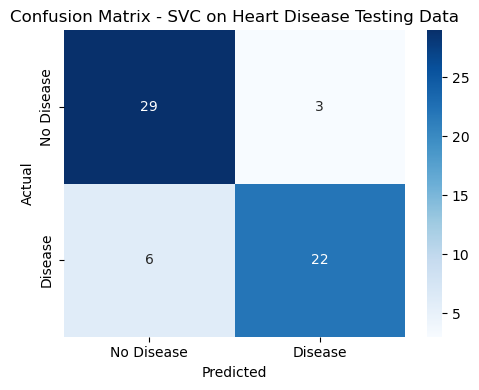

In [17]:
print(classification_report(model_predictions["Disease"], model_predictions["Predictions"],
                            target_names=["No Disease (0)", "Disease (1)"]))
conf_matrix = confusion_matrix(model_predictions["Disease"], model_predictions["Predictions"])
print(pd.DataFrame(conf_matrix,
                   index=["Actual: No Disease", "Actual: Disease"],
                   columns=["Predicted: No Disease", "Predicted: Disease"]))

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout(); plt.show()

### Step 8: Execute the Application Phase
#### Step 8.1: Take Input from User
A demo patient is pre-filled so the notebook runs top-to-bottom. For interactive use, replace the four lines with the `input()` calls shown in the comments.

In [18]:
# chestpain_input = input("Chest pain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
# gender_input = input("Gender (Male, Female): ").strip()
# exercise_angina_input = input("Exercise-induced angina (Yes, No): ").strip()
# major_vessels_input = input("Major vessels (Zero, One, Two, Three): ").strip()

chestpain_input = "Asymptomatic"
gender_input = "Male"
exercise_angina_input = "Yes"
major_vessels_input = "Two"
print(chestpain_input, gender_input, exercise_angina_input, major_vessels_input)

Asymptomatic Male Yes Two


#### Step 8.2: Convert User Input into Feature Vector

In [19]:
user_input = pd.DataFrame({
    "ChestPain": [chestpain_input],
    "Gender": [gender_input],
    "ExerciseAngina": [exercise_angina_input],
    "MajorVessels": [major_vessels_input]})
print(user_input)

      ChestPain Gender ExerciseAngina MajorVessels
0  Asymptomatic   Male            Yes          Two


#### Step 8.3: Label Encoding of Feature Vector

In [20]:
unseen_data_features = user_input.copy()
unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["Gender"] = gender_label_encoder.transform(user_input["Gender"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["MajorVessels"] = major_vessels_label_encoder.transform(user_input["MajorVessels"])
print(unseen_data_features)

   ChestPain  Gender  ExerciseAngina  MajorVessels
0          0       1               1             2


#### Step 8.4: Load the Saved Model

In [21]:
model = pickle.load(open("svc_heart_trained_model.pkl", "rb"))

#### Step 8.5: Model Prediction
##### Step 8.5.1: Apply Model and Return Prediction to the User

In [22]:
predicted_disease = model.predict(unseen_data_features)[0]
prediction = "HEART DISEASE LIKELY" if predicted_disease == 1 else "NO HEART DISEASE LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase
#### Step 9.1: Collect Feedback from Users and Domain Experts
*Illustrative feedback (simulated for this assignment, not collected from real clinicians).*

In [23]:
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Domain Expert (Cardiology)", "Student Tester"],
    "Case": [
        "Asymptomatic, Male, exercise angina Yes, 2 vessels -> predicted DISEASE",
        "Typical Angina, Female, no exercise angina, 0 vessels -> predicted NO DISEASE",
        "Model uses only 4 inputs; age, cholesterol, blood pressure are ignored",
    ],
    "Feedback": [
        "Plausible: multiple affected vessels and exercise-induced angina are strong risk signs.",
        "Plausible, but doctors would still want ECG and blood tests before ruling out disease.",
        "Limited inputs reduce reliability; important clinical measurements are missing.",
    ]})
print(example_feedback.to_string(index=False))

                  Reviewer                                                                          Case                                                                                Feedback
Domain Expert (Cardiology)       Asymptomatic, Male, exercise angina Yes, 2 vessels -> predicted DISEASE Plausible: multiple affected vessels and exercise-induced angina are strong risk signs.
Domain Expert (Cardiology) Typical Angina, Female, no exercise angina, 0 vessels -> predicted NO DISEASE  Plausible, but doctors would still want ECG and blood tests before ruling out disease.
            Student Tester        Model uses only 4 inputs; age, cholesterol, blood pressure are ignored         Limited inputs reduce reliability; important clinical measurements are missing.


#### Step 9.2: List of Potential Improvements

In [24]:
improvements = [
    "Use more attributes (age, cholesterol, resting blood pressure, max heart rate, ST depression) – the assignment limits this version to 4",
    "Use the larger multi-hospital UCI data (Hungarian, Switzerland, VA) for better generalisation",
    "Use cross-validation and compare other models (Logistic Regression, Random Forest)",
    "Tune the decision threshold or class weights to raise recall on the Disease class",
    "Replace Label Encoding with One-Hot Encoding for unordered categories such as ChestPain",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (age, cholesterol, resting blood pressure, max heart rate, ST depression) – the assignment limits this version to 4
2. Use the larger multi-hospital UCI data (Hungarian, Switzerland, VA) for better generalisation
3. Use cross-validation and compare other models (Logistic Regression, Random Forest)
4. Tune the decision threshold or class weights to raise recall on the Disease class
5. Replace Label Encoding with One-Hot Encoding for unordered categories such as ChestPain



2. Use the larger multi-hospital UCI data (Hungarian, Switzerland, VA) for better generalisation
3. Use cross-validation and compare other models (Logistic Regression, Random Forest)
4. Tune the decision threshold or class weights to raise recall on the Disease class
5. Replace Label Encoding with One-Hot Encoding for unordered categories such as ChestPain


#### Step 9.3: Improve the Model Based on Feedback
In the next version, retrain with the extra clinical attributes and cross-validation (re-running Steps 6–7), and only replace the deployed `.pkl` if recall and accuracy improve.

### Step 10: Deploy the Model to the Cloud
Files needed in the GitHub repo / hosting folder: `app.py`, `requirements.txt`, `runtime.txt`, `svc_heart_trained_model.pkl`.

1. Create a public GitHub repo and upload those files.
2. Go to https://share.streamlit.io → *New app* → pick the repo, branch `main`, main file `app.py` → *Deploy*.
3. Copy the live URL and paste it at the **very top** of this notebook.

(PythonAnywhere alternative: follow the instructor's tutorial – upload the same files, install the requirements in a virtualenv and point the web app to `app.py`/Flask.)

## Conclusion
A Support Vector Classifier was trained on four categorical patient attributes (chest pain type, gender, exercise-induced angina, number of major vessels) to predict heart disease. After fixing an inverted label and removing 5 invalid rows, the model reached 0.85 accuracy on a held-out stratified test set, with recall of 0.79 on the Disease class (see Step 7). Number of major vessels and exercise-induced angina were the clearest risk signals in the data. With only 4 inputs and 298 patients this is a teaching prototype, not a clinical tool.